# SIR epidemic model

Classical Kermack–McKendrick system integrated with `solve_ivp`. A short
sweep over the basic reproduction number $R_0 = \beta / \gamma$ makes the
herd-immunity threshold $1 - 1/R_0$ visible.

In [1]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

np.random.seed(0)

## 1. ODE system

$$\dot S = -\beta S I, \quad \dot I = \beta S I - \gamma I, \quad \dot R = \gamma I.$$

$S, I, R$ are fractions summing to 1. $R_0 = \beta / \gamma$ is the expected
number of secondary infections caused by one infectious individual in a
fully susceptible population.

In [2]:
def sir_rhs(t, y, beta, gamma):
    S, I, R = y
    return [-beta * S * I,
             beta * S * I - gamma * I,
             gamma * I]

gamma = 0.1            # recovery rate, so mean infectious period = 10 time units
R0 = 2.5
beta = R0 * gamma

y0 = [0.999, 0.001, 0.0]
t_span = (0, 160)
t_eval = np.linspace(*t_span, 400)

sol = solve_ivp(sir_rhs, t_span, y0, t_eval=t_eval, args=(beta, gamma),
                rtol=1e-8, atol=1e-10)
S, I, R = sol.y

## 2. Baseline trajectory ($R_0 = 2.5$)

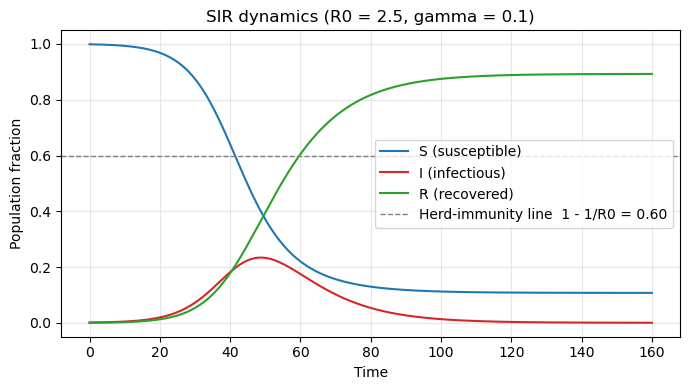

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sol.t, S, label="S (susceptible)", color="tab:blue")
ax.plot(sol.t, I, label="I (infectious)",  color="tab:red")
ax.plot(sol.t, R, label="R (recovered)",   color="tab:green")
ax.axhline(1 - 1 / R0, ls="--", color="gray", lw=1,
           label=f"Herd-immunity line  1 - 1/R0 = {1 - 1/R0:.2f}")
ax.set_xlabel("Time")
ax.set_ylabel("Population fraction")
ax.set_title(f"SIR dynamics (R0 = {R0}, gamma = {gamma})")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Sweep over $R_0$

In [4]:
R0_values = [0.8, 1.2, 1.8, 2.5, 4.0]
results = {}
for R0v in R0_values:
    beta_v = R0v * gamma
    sv = solve_ivp(sir_rhs, t_span, y0, t_eval=t_eval, args=(beta_v, gamma),
                   rtol=1e-8, atol=1e-10)
    results[R0v] = sv.y

### Infectious curves

- $R_0 < 1$: no outbreak, $I$ decays monotonically.
- $R_0 > 1$: epidemic. Peak and total attack rate grow with $R_0$.

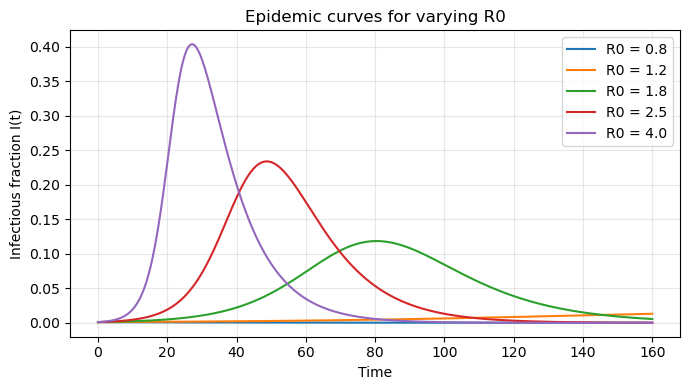

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
for R0v in R0_values:
    ax.plot(t_eval, results[R0v][1], label=f"R0 = {R0v}")
ax.set_xlabel("Time")
ax.set_ylabel("Infectious fraction I(t)")
ax.set_title("Epidemic curves for varying R0")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Final epidemic size vs $R_0$

The final size $R_\infty$ (fraction ever infected) satisfies the implicit
relation $1 - R_\infty = e^{-R_0 R_\infty}$. Compare the numerical endpoint
against the herd-immunity threshold $1 - 1/R_0$.

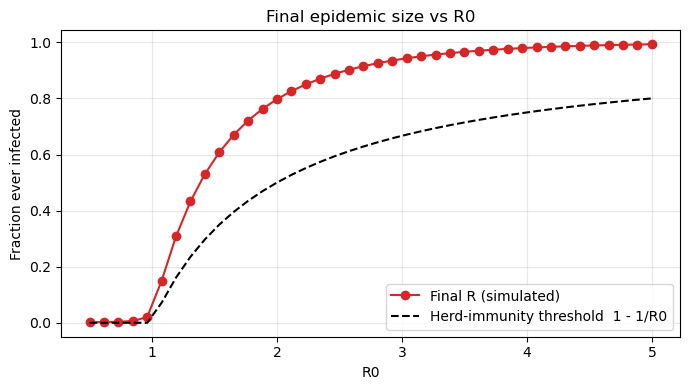

In [6]:
R0_grid = np.linspace(0.5, 5.0, 40)
final_R = []
for R0v in R0_grid:
    beta_v = R0v * gamma
    sv = solve_ivp(sir_rhs, (0, 1000), y0, args=(beta_v, gamma),
                   rtol=1e-9, atol=1e-11)
    final_R.append(sv.y[2, -1])
final_R = np.array(final_R)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(R0_grid, final_R, "o-", color="tab:red", label="Final R (simulated)")
ax.plot(R0_grid, np.where(R0_grid > 1, 1 - 1 / R0_grid, 0),
        "k--", label="Herd-immunity threshold  1 - 1/R0")
ax.set_xlabel("R0")
ax.set_ylabel("Fraction ever infected")
ax.set_title("Final epidemic size vs R0")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Exercises

1. Add a vital dynamics term (births and deaths at rate $\mu$) and show that
   an endemic equilibrium $I^* > 0$ emerges when $R_0 > 1$.
2. Extend to an SEIR model (adding an "exposed" compartment with incubation
   rate $\sigma$). Compare peak timing against SIR for the same $R_0$.
3. Solve the implicit final-size equation $1 - x = e^{-R_0 x}$ with
   `scipy.optimize.brentq` and overlay it on the simulated curve above.